# Klasifikasi URL Phishing vs Legitimate (URL Reguler dan Punycode)

Notebook ini membangun eksperimen **Multinomial Naive Bayes** untuk membedakan URL phishing dan legitimate menggunakan empat kelompok data: 65.000 URL Tranco, 65.000 URL PhishTank, 5.000 URL Punycode legitimate, dan 5.000 URL Punycode phishing. Alur mencakup validasi data, eksplorasi, ekstraksi fitur TF-IDF berbasis karakter, pelatihan, evaluasi metrik, visualisasi, dan analisis kesalahan.

> **Catatan metodologis:** kedua dataset merupakan varian homograf sintetis. Label diwarisi dari sumber awal dan tidak berarti hostname hasil transformasi telah diverifikasi aktif. Model ini ditujukan untuk eksperimen pola leksikal URL, bukan sistem produksi tunggal untuk memblokir situs.

## 1. Persiapan lingkungan

Memuat pustaka, menetapkan seed agar hasil dapat direproduksi, serta mengatur gaya visualisasi. Jika pustaka belum tersedia, instal `pandas`, `numpy`, `scikit-learn`, `matplotlib`, dan `seaborn` terlebih dahulu.

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
)

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold"})

print("Lingkungan siap. Seed:", SEED)

Lingkungan siap. Seed: 42


## 2. Memuat empat kelompok dataset

Komposisi eksperimen adalah:

- 65.000 domain teratas Tranco sebagai legitimate reguler.
- 65.000 URL `verified_online.csv` dari PhishTank sebagai phishing reguler.
- 5.000 URL Punycode legitimate.
- 5.000 URL Punycode phishing.

Total data adalah 140.000 URL, seimbang antara 70.000 legitimate dan 70.000 phishing. Kolom `source_url` dari CSV Punycode tidak digunakan sebagai fitur untuk mencegah kebocoran informasi.

In [2]:
BASE_DIR = Path.cwd()
if not (BASE_DIR / "tranco_6WNKX.csv").exists():
    BASE_DIR = Path(".").resolve()

N_REGULAR = 65_000

# Muat Punycode lebih dulu dan simpan URL asal sebagai kunci grup.
legitimate_punycode_raw = pd.read_csv(BASE_DIR / "legitimate_punycode_5000.csv").head(5_000)
phishing_punycode_raw = pd.read_csv(BASE_DIR / "phishing_punycode_5000.csv").head(5_000)

legitimate_punycode = legitimate_punycode_raw[["url", "label", "source_url"]].rename(
    columns={"source_url": "source_key"}
).assign(source_dataset="Legitimate (Punycode)")
phishing_punycode = phishing_punycode_raw[["url", "label", "source_url"]].rename(
    columns={"source_url": "source_key"}
).assign(source_dataset="Phishing (Punycode)")

# Siapkan kandidat Tranco lebih banyak; konflik lintas kelas disaring setelah
# 65.000 URL PhishTank dipilih.
tranco = pd.read_csv(BASE_DIR / "tranco_6WNKX.csv", header=None,
                     names=["rank", "domain"], nrows=70_000)
tranco = tranco.drop_duplicates(subset="domain")

# Ambil tepat 65.000 URL unik PhishTank.
phishtank_raw = pd.read_csv(BASE_DIR / "verified_online.csv")
phishtank_raw = phishtank_raw.drop_duplicates(subset="url")
phishtank_raw = phishtank_raw.head(N_REGULAR)
phishtank_df = pd.DataFrame({
    "url": phishtank_raw["url"].astype(str).str.strip(),
    "label": "phishing",
    "source_dataset": "PhishTank (regular)",
    "source_key": phishtank_raw["url"].astype(str).str.strip(),
})

phishing_url_set = set(phishtank_df["url"])
tranco = tranco[
    ~("https://" + tranco["domain"].astype(str).str.strip()).isin(phishing_url_set)
].head(N_REGULAR)
tranco_df = pd.DataFrame({
    "url": "https://" + tranco["domain"].astype(str).str.strip(),
    "label": "legitimate",
    "source_dataset": "Tranco (regular)",
    "source_key": tranco["domain"].astype(str).str.strip(),
})

df = pd.concat(
    [tranco_df, phishtank_df, legitimate_punycode, phishing_punycode],
    ignore_index=True,
)

source_summary = df.groupby(["source_dataset", "label"]).size().rename("jumlah").reset_index()
display(source_summary)
print(f"Total gabungan: {len(df):,} baris")
display(df.head())

,source_dataset,label,jumlah
0,Legitimate (Punycode),legitimate,5000
1,PhishTank (regular),phishing,65000
2,Phishing (Punycode),phishing,5000
3,Tranco (regular),legitimate,65000


Total gabungan: 140,000 baris


,url,label,source_dataset,source_key
0,https://google.com,legitimate,Tranco (regular),google.com
1,https://gtld-servers.net,legitimate,Tranco (regular),gtld-servers.net
2,https://cloudflare.com,legitimate,Tranco (regular),cloudflare.com
3,https://gstatic.com,legitimate,Tranco (regular),gstatic.com
4,https://facebook.com,legitimate,Tranco (regular),facebook.com


## 3. Audit kualitas data

Tahap ini memeriksa struktur kolom, nilai kosong, duplikasi URL, konsistensi label, dan keberadaan label Punycode `xn--`. Duplikasi harus dibuang sebelum pembagian data agar URL identik tidak muncul pada train dan test sekaligus.

In [3]:
required_columns = {"url", "label"}
missing_columns = required_columns - set(df.columns)
assert not missing_columns, f"Kolom wajib tidak ditemukan: {missing_columns}"

audit = pd.Series({
    "jumlah_baris": len(df),
    "url_kosong": df["url"].isna().sum(),
    "label_kosong": df["label"].isna().sum(),
    "url_duplikat": df["url"].duplicated().sum(),
    "jumlah_label": df["label"].nunique(),
    "url_punycode": df["url"].str.contains("xn--", case=False, na=False).sum(),
}, name="nilai")
display(audit.to_frame())

df = df.dropna(subset=["url", "label"]).drop_duplicates(subset="url").copy()
df["url"] = df["url"].astype(str).str.strip()
df["label"] = df["label"].str.lower().str.strip()
assert set(df["label"]) == {"legitimate", "phishing"}
assert len(df) == 140_000, "Jumlah berkurang setelah pembersihan; periksa duplikasi atau data kosong."
synthetic_punycode_count = df["source_dataset"].str.contains("Punycode").sum()
assert synthetic_punycode_count == 10_000
print(f"Audit selesai: 140.000 URL unik dan {synthetic_punycode_count:,} URL Punycode sintetis.")
print(f"Total URL yang memuat xn-- (termasuk IDN alami): {df['url'].str.contains('xn--', case=False).sum():,}")

,nilai
jumlah_baris,140000
url_kosong,0
label_kosong,0
url_duplikat,0
jumlah_label,2
url_punycode,10133


Audit selesai: 140.000 URL unik dan 10,000 URL Punycode sintetis.


Total URL yang memuat xn-- (termasuk IDN alami): 10,133


## 4. Validasi IDNA/Punycode

Hostname diekstrak dari URL. Setiap hostname yang memuat `xn--` dicoba didekode dengan codec IDNA. Ini mencakup 10.000 Punycode sintetis dan IDN alami yang mungkin sudah ada pada dataset reguler.

In [4]:
def get_hostname(url):
    return (urlsplit(url).hostname or "").lower()

def decode_idna(hostname):
    try:
        return hostname.encode("ascii").decode("idna")
    except (UnicodeError, UnicodeEncodeError):
        return None

df["hostname"] = df["url"].map(get_hostname)
df["is_punycode"] = df["url"].str.contains("xn--", case=False)
df["is_synthetic_punycode"] = df["source_dataset"].str.contains("Punycode")
df["unicode_hostname"] = df["hostname"].map(decode_idna)
invalid_idna = df.loc[df["is_punycode"], "unicode_hostname"].isna().sum()
invalid_synthetic = df.loc[df["is_synthetic_punycode"], "unicode_hostname"].isna().sum()

print("URL Punycode diperiksa:", f"{df['is_punycode'].sum():,}")
print("Hostname IDNA valid  :", f"{df['is_punycode'].sum() - invalid_idna:,}")
print("Hostname IDNA invalid:", f"{invalid_idna:,}")
print("Punycode sintetis invalid:", f"{invalid_synthetic:,}")
assert invalid_synthetic == 0, "Terdapat Punycode sintetis yang tidak valid."
display(df[["url", "hostname", "unicode_hostname", "label"]].head(8))

URL Punycode diperiksa: 10,133
Hostname IDNA valid  : 10,132
Hostname IDNA invalid: 1
Punycode sintetis invalid: 0


,url,hostname,unicode_hostname,label
0,https://google.com,google.com,google.com,legitimate
1,https://gtld-servers.net,gtld-servers.net,gtld-servers.net,legitimate
2,https://cloudflare.com,cloudflare.com,cloudflare.com,legitimate
3,https://gstatic.com,gstatic.com,gstatic.com,legitimate
4,https://facebook.com,facebook.com,facebook.com,legitimate
5,https://microsoft.com,microsoft.com,microsoft.com,legitimate
6,https://googleapis.com,googleapis.com,googleapis.com,legitimate
7,https://youtube.com,youtube.com,youtube.com,legitimate


## 5. Exploratory Data Analysis (EDA)

Fitur deskriptif berikut **bukan** masukan langsung model; fitur ini membantu memahami perbedaan distribusi kedua kelas. Entropi Shannon mengukur keragaman karakter pada URL.

In [5]:
def shannon_entropy(text):
    probabilities = pd.Series(list(text)).value_counts(normalize=True)
    return float(-(probabilities * np.log2(probabilities)).sum())

df["url_length"] = df["url"].str.len()
df["hostname_length"] = df["hostname"].str.len()
df["dot_count"] = df["hostname"].str.count(r"\.")
df["hyphen_count"] = df["hostname"].str.count("-")
df["digit_count"] = df["url"].str.count(r"\d")
df["special_count"] = df["url"].str.count(r"[^A-Za-z0-9]")
df["has_query"] = df["url"].str.contains(r"\?", regex=True).astype(int)
df["entropy"] = df["url"].map(shannon_entropy)

eda_columns = ["url_length", "hostname_length", "dot_count", "hyphen_count",
               "digit_count", "special_count", "has_query", "entropy"]
display(df.groupby("label")[eda_columns].agg(["mean", "median", "std"]).round(2))

url_length                hostname_length               dot_count  \
                 mean median     std            mean median    std      mean   
label                                                                          
legitimate      20.81   20.0    4.15           12.81   12.0   4.15      1.09   
phishing        57.59   39.0  150.14           21.18   19.0  13.16      1.79   

                        hyphen_count  ... digit_count special_count         \
           median   std         mean  ...         std          mean median   
label                                 ...                                    
legitimate    1.0  0.28         0.30  ...        0.74          4.39    4.0   
phishing      2.0  0.56         0.69  ...       22.01          9.04    7.0   

                 has_query              entropy               
             std      mean median   std    mean median   std  
label                                                         
legitimate  0.87      0.00    0.0  0.00    3.72   3.73  0.23  
phishing    6.69      0.16    0.0  0.36    4.33   4.17  0.51  

[2 rows x 24 columns]

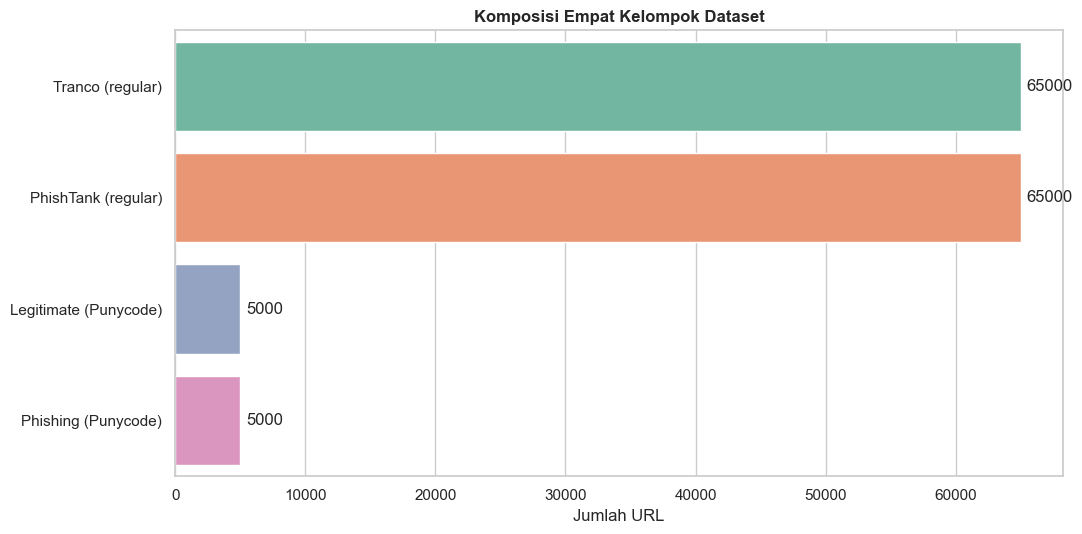

In [6]:
source_counts = df["source_dataset"].value_counts().rename_axis("Sumber").reset_index(name="Jumlah")
plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=source_counts, y="Sumber", x="Jumlah", hue="Sumber",
                 palette="Set2", legend=False)
ax.set_title("Komposisi Empat Kelompok Dataset")
ax.set_xlabel("Jumlah URL")
ax.set_ylabel("")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4)
plt.tight_layout()
plt.show()

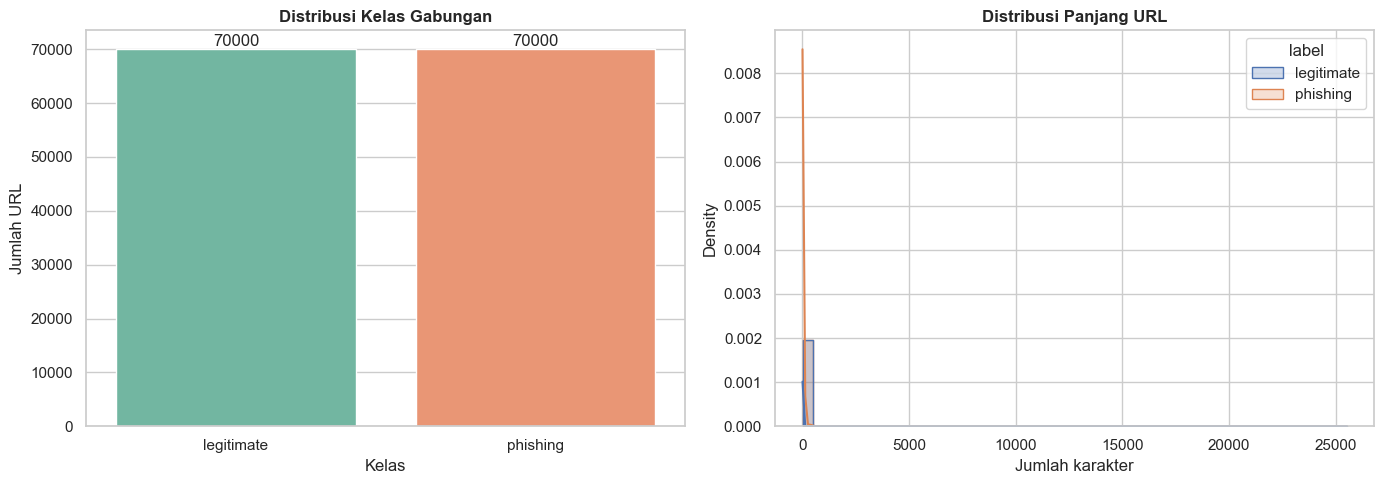

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="label", hue="label", palette="Set2", legend=False, ax=axes[0])
axes[0].set(title="Distribusi Kelas Gabungan", xlabel="Kelas", ylabel="Jumlah URL")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d")

sns.histplot(data=df, x="url_length", hue="label", bins=50, kde=True,
             element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set(title="Distribusi Panjang URL", xlabel="Jumlah karakter", ylabel="Density")

plt.tight_layout()
plt.show()

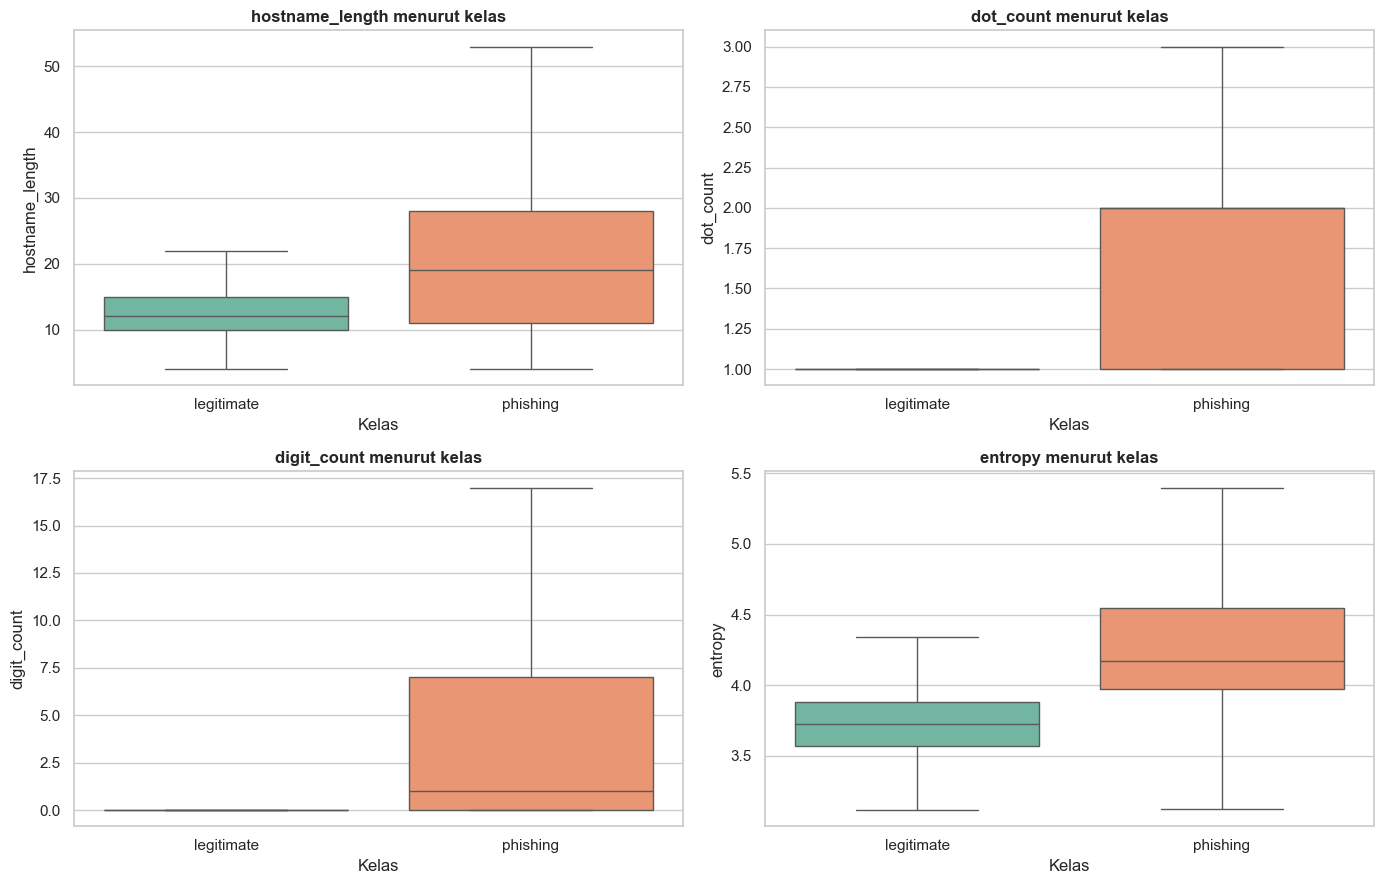

In [8]:
features_to_plot = ["hostname_length", "dot_count", "digit_count", "entropy"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for feature, ax in zip(features_to_plot, axes.flat):
    sns.boxplot(data=df, x="label", y=feature, hue="label", palette="Set2", legend=False,
                showfliers=False, ax=ax)
    ax.set_title(f"{feature} menurut kelas")
    ax.set_xlabel("Kelas")
plt.tight_layout()
plt.show()

## 6. Menyiapkan target dan group-aware split

Target dikodekan menjadi `0 = legitimate` dan `1 = phishing`. Pembagian dilakukan per kelas dengan `GroupShuffleSplit` 80:20 menggunakan `source_key`. Dengan demikian, URL reguler dan versi Punycode yang berasal dari URL sama tidak pernah tersebar di train dan test. Data test juga tidak ikut dalam pembentukan vocabulary TF-IDF.

In [9]:
X = df["url"]
y = df["label"].map({"legitimate": 0, "phishing": 1})

train_indices, test_indices = [], []
for class_value in [0, 1]:
    class_indices = df.index[y == class_value].to_numpy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    local_train, local_test = next(splitter.split(
        class_indices,
        groups=df.loc[class_indices, "source_key"],
    ))
    train_indices.extend(class_indices[local_train])
    test_indices.extend(class_indices[local_test])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)
X_train, X_test = X.loc[train_indices], X.loc[test_indices]
y_train, y_test = y.loc[train_indices], y.loc[test_indices]

train_groups = set(df.loc[train_indices, "source_key"])
test_groups = set(df.loc[test_indices, "source_key"])
assert train_groups.isdisjoint(test_groups), "Terjadi kebocoran grup antara train dan test."

split_summary = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
}).rename(index={0: "legitimate", 1: "phishing"})
display(split_summary)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
print("Grup train dan test tumpang tindih: 0")

,train,test
label,,
legitimate,56009,13991
phishing,56033,13967


Train: 112,042 | Test: 27,958
Grup train dan test tumpang tindih: 0


## 7. Ekstraksi fitur dan pelatihan Naive Bayes

TF-IDF karakter dipilih karena fragmen domain, path, angka, tanda hubung, dan urutan karakter Punycode bersifat informatif. Rentang n-gram 3-5 menangkap pola lokal tanpa harus memahami token bahasa. `MultinomialNB` sesuai untuk fitur non-negatif seperti TF-IDF.

Seluruh tahap dimasukkan ke `Pipeline`, sehingga vectorizer hanya belajar dari data train.

In [10]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        max_features=60_000,
        sublinear_tf=True,
        lowercase=True,
    )),
    ("nb", MultinomialNB(alpha=0.1)),
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model selesai dilatih.")
print("Jumlah fitur TF-IDF:", len(model.named_steps["tfidf"].get_feature_names_out()))

Model selesai dilatih.
Jumlah fitur TF-IDF: 60000


## 8. Evaluasi metrik klasifikasi

- **Accuracy:** proporsi seluruh prediksi yang benar.
- **Precision phishing:** dari semua URL yang diprediksi phishing, berapa yang benar phishing.
- **Recall phishing:** dari semua phishing, berapa yang berhasil ditemukan.
- **F1-score:** rata-rata harmonik precision dan recall.
- **ROC-AUC / PR-AUC:** kualitas pemeringkatan probabilitas pada berbagai threshold.

In [11]:
metrics = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"],
    "Nilai": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob),
    ],
})
metrics["Nilai (%)"] = (metrics["Nilai"] * 100).round(2)
display(metrics)

print(classification_report(
    y_test, y_pred,
    target_names=["legitimate", "phishing"],
    digits=4,
))

,Metrik,Nilai,Nilai (%)
0,Accuracy,0.973925,97.39
1,Precision,0.987336,98.73
2,Recall,0.960120,96.01
3,F1-score,0.973538,97.35
4,ROC-AUC,0.994441,99.44
5,PR-AUC,0.995613,99.56


              precision    recall  f1-score   support

  legitimate     0.9613    0.9877    0.9743     13991
    phishing     0.9873    0.9601    0.9735     13967

    accuracy                         0.9739     27958
   macro avg     0.9743    0.9739    0.9739     27958
weighted avg     0.9743    0.9739    0.9739     27958



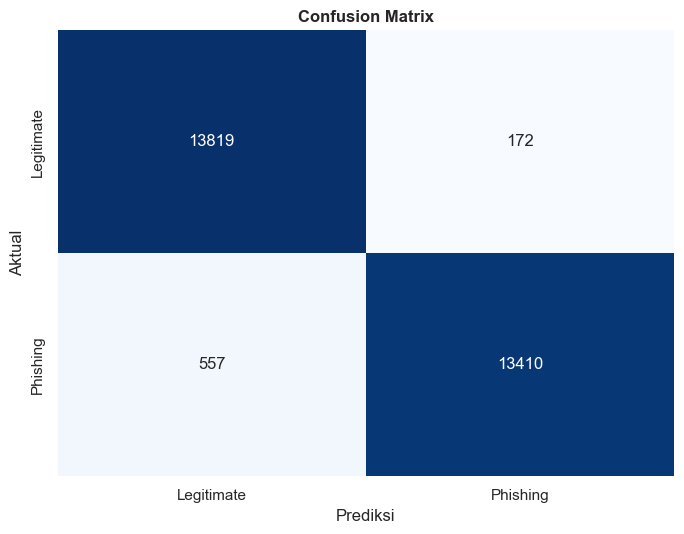

TN=13819, FP=172, FN=557, TP=13410


In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Legitimate", "Phishing"],
            yticklabels=["Legitimate", "Phishing"])
plt.title("Confusion Matrix")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

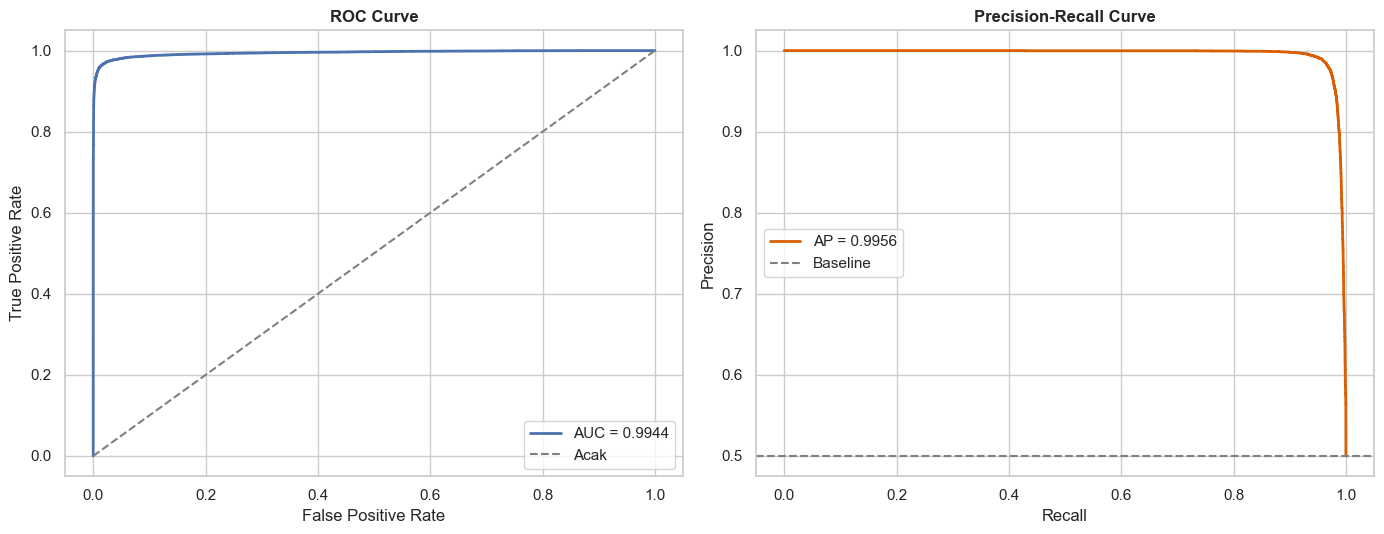

In [13]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
pr_precision, pr_recall, _ = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, y_prob):.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Acak")
axes[0].set(title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[0].legend()

axes[1].plot(pr_recall, pr_precision, lw=2,
             label=f"AP = {average_precision_score(y_test, y_prob):.4f}", color="#d95f02")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Baseline")
axes[1].set(title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Pola karakter paling informatif

MultinomialNB menyimpan log-probability setiap fitur per kelas. Selisih log-probability digunakan untuk menampilkan n-gram yang relatif lebih kuat bagi masing-masing kelas. Interpretasi ini menunjukkan korelasi, bukan hubungan sebab-akibat.

,N-gram phishing,Skor phishing,N-gram legitimate,Skor legitimate
0,om/,8.727,sdns-,6.965
1,com/,8.726,wsdns,6.963
2,.com/,8.717,awsdn,6.856
3,e/b,8.424,/awsd,6.856
4,de/,8.071,wsdn,6.453
5,.de/,8.064,casin,6.390
6,o.de/,8.052,asino,6.387
7,rco.d,8.051,/nic.,6.346
8,qrco.,8.051,ov.i,6.203
9,de/b,8.037,gov.i,6.179


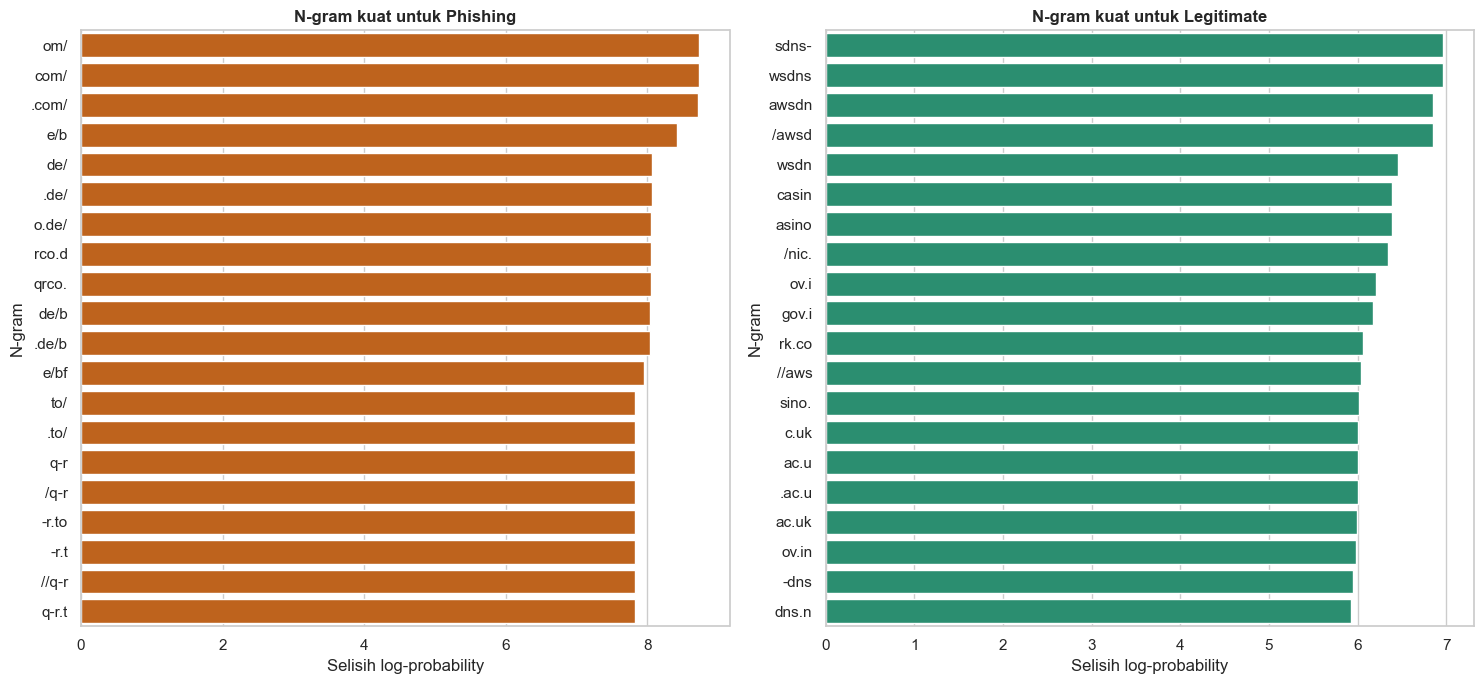

In [14]:
feature_names = model.named_steps["tfidf"].get_feature_names_out()
log_prob = model.named_steps["nb"].feature_log_prob_
feature_score = log_prob[1] - log_prob[0]
top_n = 20

top_phishing_idx = np.argsort(feature_score)[-top_n:][::-1]
top_legitimate_idx = np.argsort(feature_score)[:top_n]

important_features = pd.DataFrame({
    "N-gram phishing": feature_names[top_phishing_idx],
    "Skor phishing": feature_score[top_phishing_idx].round(3),
    "N-gram legitimate": feature_names[top_legitimate_idx],
    "Skor legitimate": (-feature_score[top_legitimate_idx]).round(3),
})
display(important_features)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
sns.barplot(x=feature_score[top_phishing_idx], y=feature_names[top_phishing_idx],
            color="#d95f02", ax=axes[0])
axes[0].set(title="N-gram kuat untuk Phishing", xlabel="Selisih log-probability", ylabel="N-gram")
sns.barplot(x=-feature_score[top_legitimate_idx], y=feature_names[top_legitimate_idx],
            color="#1b9e77", ax=axes[1])
axes[1].set(title="N-gram kuat untuk Legitimate", xlabel="Selisih log-probability", ylabel="N-gram")
plt.tight_layout()
plt.show()

## 10. Analisis kesalahan

False positive adalah URL legitimate yang diprediksi phishing, sedangkan false negative adalah URL phishing yang lolos sebagai legitimate. Contoh berprobabilitas paling meyakinkan ditampilkan untuk membantu audit model.

In [15]:
results = pd.DataFrame({
    "url": X_test,
    "aktual": y_test,
    "prediksi": y_pred,
    "prob_phishing": y_prob,
}).reset_index(drop=True)
results["aktual_label"] = results["aktual"].map({0: "legitimate", 1: "phishing"})
results["prediksi_label"] = results["prediksi"].map({0: "legitimate", 1: "phishing"})

false_positive = results[(results["aktual"] == 0) & (results["prediksi"] == 1)]     .sort_values("prob_phishing", ascending=False)
false_negative = results[(results["aktual"] == 1) & (results["prediksi"] == 0)]     .sort_values("prob_phishing", ascending=True)

print(f"False positive: {len(false_positive)}")
display(false_positive[["url", "aktual_label", "prediksi_label", "prob_phishing"]].head(10))
print(f"False negative: {len(false_negative)}")
display(false_negative[["url", "aktual_label", "prediksi_label", "prob_phishing"]].head(10))

False positive: 172


,url,aktual_label,prediksi_label,prob_phishing
3170,https://qrco.de,legitimate,phishing,1.000000
933,https://campaign-archive.com,legitimate,phishing,0.999984
13160,https://xn--llegro-2nf.pl,legitimate,phishing,0.999960
2642,https://campaign-archive1.com,legitimate,phishing,0.999947
164,https://allegro.pl,legitimate,phishing,0.999911
3054,https://ipfs.io,legitimate,phishing,0.999883
1693,https://allegro.hu,legitimate,phishing,0.999493
59,https://linktr.ee,legitimate,phishing,0.999456
13908,https://xn--ampaign-archive-ltm.com,legitimate,phishing,0.999363
7824,https://bfs.de,legitimate,phishing,0.998570


False negative: 557


,url,aktual_label,prediksi_label,prob_phishing
19757,https://marketplace.uat.mksiegowosc.cashdirect...,phishing,legitimate,0.000041
17498,https://pinko.com.pl,phishing,legitimate,0.000099
26579,https://lifelonghealthclub.com/,phishing,legitimate,0.000119
27832,https://xn--mchmach-rog.com,phishing,legitimate,0.000133
14842,https://fashionnvren.com,phishing,legitimate,0.000136
14818,https://lsmetalmesh.com,phishing,legitimate,0.000159
17267,https://cheiseagrotton.company,phishing,legitimate,0.000163
14845,https://mukamusiccenter.com,phishing,legitimate,0.000168
26978,http://syneoshealthlondon.co.uk.mcas.ms,phishing,legitimate,0.000176
20273,https://patrickeichelba.samcart.com,phishing,legitimate,0.000201


## 11. Distribusi probabilitas dan threshold

Threshold default adalah 0,5. Dalam sistem keamanan, threshold dapat diturunkan untuk meningkatkan recall phishing, dengan konsekuensi false positive bertambah. Grafik berikut memperlihatkan seberapa baik probabilitas kedua kelas terpisah.

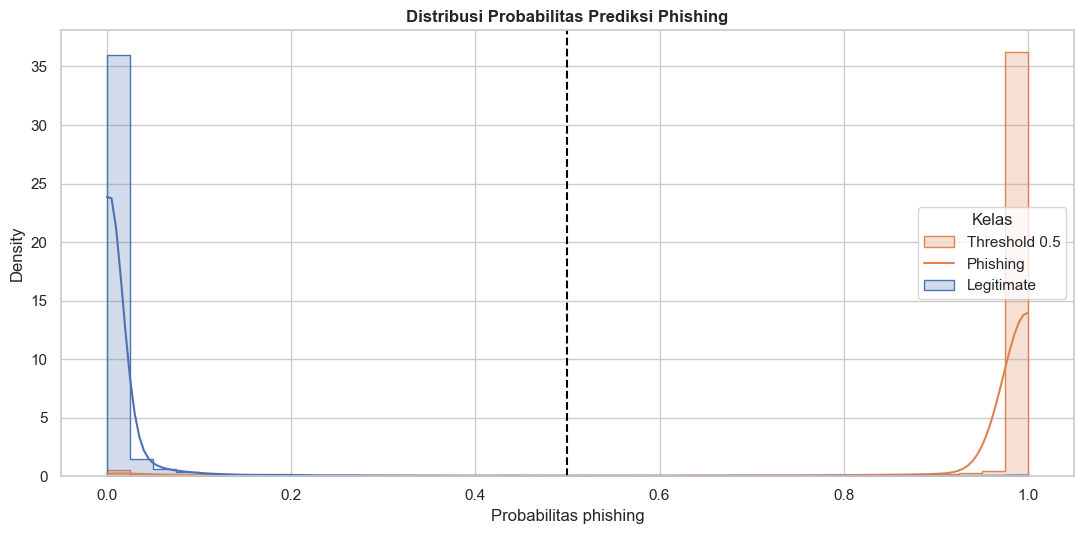

In [16]:
plot_results = results.copy()
plot_results["Kelas aktual"] = plot_results["aktual_label"].str.title()

plt.figure(figsize=(11, 5.5))
sns.histplot(data=plot_results, x="prob_phishing", hue="Kelas aktual",
             bins=40, kde=True, element="step", stat="density", common_norm=False)
plt.axvline(0.5, color="black", linestyle="--", label="Threshold 0.5")
plt.title("Distribusi Probabilitas Prediksi Phishing")
plt.xlabel("Probabilitas phishing")
plt.ylabel("Density")
plt.legend(title="Kelas", labels=["Threshold 0.5", "Phishing", "Legitimate"])
plt.tight_layout()
plt.show()

## 12. Fungsi prediksi URL baru

Fungsi berikut mengembalikan label dan probabilitas. Masukan harus berupa URL Punycode atau URL yang formatnya serupa dengan data pelatihan.

In [17]:
def predict_urls(urls):
    urls = pd.Series(urls, name="url")
    probabilities = model.predict_proba(urls)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    return pd.DataFrame({
        "url": urls,
        "prediksi": np.where(predictions == 1, "phishing", "legitimate"),
        "probabilitas_phishing": probabilities.round(4),
    })

sample_urls = df.groupby("label", group_keys=False).sample(2, random_state=SEED)["url"].tolist()
display(predict_urls(sample_urls))

,url,prediksi,probabilitas_phishing
0,https://dominos.co.uk,legitimate,0.0000
1,https://myoji-yurai.net,legitimate,0.0004
2,https://xn--nv-velldrome-x9j.wixstudio.com/en-us,phishing,1.0000
3,https://ledgr-livedesktop.wixstudio.com/us-en,phishing,1.0000


## 13. Kesimpulan dan batasan

1. Pipeline mempelajari n-gram karakter langsung dari URL Punycode dan dievaluasi pada test set yang tidak digunakan saat membentuk vocabulary.
2. Accuracy tidak dibaca sendirian; precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix, dan contoh kesalahan memberi gambaran lebih lengkap.
3. Dataset seimbang, tetapi 10.000 URL Punycode bersifat sintetis; hasil dapat lebih tinggi daripada performa pada lalu lintas internet nyata. Group-aware split menjaga URL sumber dan transformasi Punycode tetap pada partisi yang sama untuk mencegah kebocoran pasangan.
4. Random split mengukur generalisasi pada distribusi yang sama. Evaluasi lanjutan sebaiknya memakai **time-based split**, domain yang benar-benar baru, dan sumber eksternal.
5. Untuk penggunaan operasional, gabungkan fitur URL dengan reputasi domain, umur domain, DNS/TLS, redirect, serta konten halaman. Jangan mengunjungi URL phishing secara langsung ketika melakukan validasi.